# EXPT NO: 9 — TEXT CLASSIFICATION AND TEXT GENERATION USING TRANSFORMERS
**Name:** Abhishek J  -  **Roll No:** 24BAD002

In [1]:
%pip install -q transformers datasets accelerate scikit-learn

In [2]:
import re, textwrap
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoModelForSeq2SeqLM,
                          TrainingArguments, Trainer, pipeline, set_seed)
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)

STUDENT, ROLL_NO = "Abhishek J", "24BAD002"
SEED, MAX_LEN, N_TRAIN, N_TEST = 42, 256, 8000, 2000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ID2LABEL = {0: "NEGATIVE", 1: "POSITIVE"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
set_seed(SEED)

def banner(title):
    print(f"{'=' * 64}\n{title}  |  {STUDENT}  |  Roll No: {ROLL_NO}\n{'=' * 64}")

banner("SETUP")
print("Device:", DEVICE, "| PyTorch", torch.__version__)

SETUP  |  Abhishek J  |  Roll No: 24BAD002
Device: cuda | PyTorch 2.11.0+cu130


## PART A: DATASET PREPARATION AND TEXT PREPROCESSING

In [3]:
banner("PART A: DATASET PREPARATION")
raw = load_dataset("stanfordnlp/imdb")          # predefined splits (the 'unsupervised' split is unused)
print(raw, "\n")

print("Class distribution (full splits):")
print(pd.DataFrame({s: pd.Series(raw[s]["label"]).map(ID2LABEL).value_counts() for s in ["train", "test"]}), "\n")

print("Sample entries:")
for i in (0, len(raw["train"]) - 1):
    ex = raw["train"][i]
    print(f"[{ID2LABEL[ex['label']]}] {ex['text'][:300]}...\n")

PART A: DATASET PREPARATION  |  Abhishek J  |  Roll No: 24BAD002


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
}) 

Class distribution (full splits):
          train   test
NEGATIVE  12500  12500
POSITIVE  12500  12500 

Sample entries:
[NEGATIVE] I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h...

[POSITIVE] The story centers around Barry McKenzie who must go to England if he wishes to claim his inheritance. Being about the grossest Aussie shearer ever to set foot outside this great Nation of ours there is something of a culture clash and much fun and games ensue.

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Train: 8000 samples | Test: 2000 samples
          train  test
NEGATIVE   4000  1000
POSITIVE   4000  1000


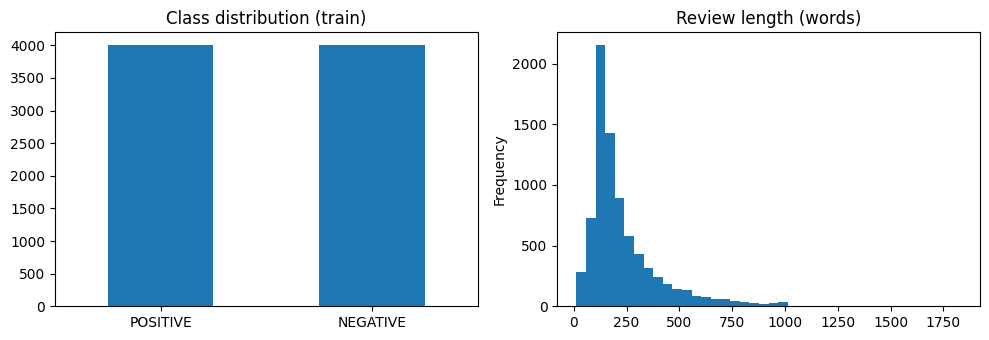

In [4]:
# Stratified subsets from the predefined splits + light cleaning (remove HTML line breaks)
def subset(split, n):
    return raw[split].train_test_split(train_size=n, stratify_by_column="label", seed=SEED)["train"]

def clean(batch):
    return {"text": [t.replace("<br />", " ") for t in batch["text"]]}

train_ds = subset("train", N_TRAIN).map(clean, batched=True)
test_ds = subset("test", N_TEST).map(clean, batched=True)

print(f"Train: {len(train_ds)} samples | Test: {len(test_ds)} samples")
print(pd.DataFrame({"train": pd.Series(train_ds["label"]).map(ID2LABEL).value_counts(),
                    "test": pd.Series(test_ds["label"]).map(ID2LABEL).value_counts()}))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
pd.Series(train_ds["label"]).map(ID2LABEL).value_counts().plot.bar(ax=ax[0], rot=0, title="Class distribution (train)")
pd.Series(train_ds["text"]).str.split().str.len().plot.hist(bins=40, ax=ax[1], title="Review length (words)")
plt.tight_layout(); plt.show()

In [5]:
# Tokenization with the BERT tokenizer: padding + truncation to a fixed length
MODEL = "bert-base-uncased"
tok = AutoTokenizer.from_pretrained(MODEL)

enc = tok(train_ds[0]["text"], truncation=True, padding="max_length", max_length=MAX_LEN)
print("Tokens   :", tok.convert_ids_to_tokens(enc["input_ids"][:12]))
print("Token IDs:", enc["input_ids"][:12])
print(f"Length: {len(enc['input_ids'])} | padded positions: {enc['attention_mask'].count(0)}")

def tokenize(batch):
    return tok(batch["text"], truncation=True, padding="max_length", max_length=MAX_LEN)

def prepare(ds):
    ds = ds.map(tokenize, batched=True).rename_column("label", "labels")
    ds.set_format("torch", columns=["input_ids", "token_type_ids", "attention_mask", "labels"])
    return ds

tok_train, tok_test = prepare(train_ds), prepare(test_ds)

# Batch-wise processing
batch = next(iter(DataLoader(tok_train, batch_size=16, shuffle=True)))
print("\nOne training batch:", {k: tuple(v.shape) for k, v in batch.items()})

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokens   : ['[CLS]', 'male', '##fi', '##que', 'pretty', 'much', 'has', 'the', 'viewer', 'from', 'start', 'to']
Token IDs: [101, 3287, 8873, 4226, 3492, 2172, 2038, 1996, 13972, 2013, 2707, 2000]
Length: 256 | padded positions: 0


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]


One training batch: {'labels': (16,), 'input_ids': (16, 256), 'token_type_ids': (16, 256), 'attention_mask': (16, 256)}


## PART B: FINE-TUNING BERT FOR TEXT CLASSIFICATION

In [6]:
banner("PART B: FINE-TUNING BERT")
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID)

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    prec, rec, f1, _ = precision_recall_fscore_support(p.label_ids, preds, average="binary")
    return {"accuracy": accuracy_score(p.label_ids, preds), "precision": prec, "recall": rec, "f1": f1}

args = TrainingArguments(
    output_dir="bert_imdb",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    seed=SEED,
    report_to="none",
)
trainer = Trainer(model=model, args=args, train_dataset=tok_train,
                  eval_dataset=tok_test, compute_metrics=compute_metrics)
trainer.train()

PART B: FINE-TUNING BERT  |  Abhishek J  |  Roll No: 24BAD002


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.258859,0.236741,0.913000,0.920570,0.904000,0.912210
2,0.182724,0.279881,0.917000,0.922065,0.911000,0.916499


TrainOutput(global_step=1000, training_loss=0.25070671606063843, metrics={'train_runtime': 247.8508, 'train_samples_per_second': 64.555, 'train_steps_per_second': 4.035, 'total_flos': 2104888442880000.0, 'train_loss': 0.25070671606063843, 'epoch': 2.0})

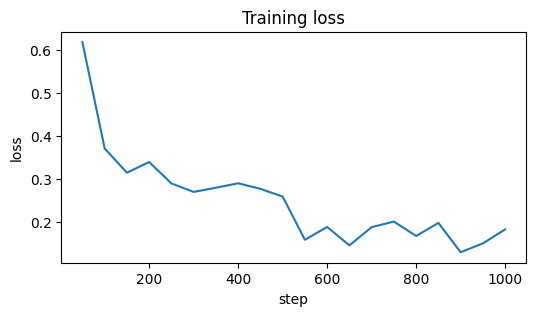

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.182724,0.279881,2,0.917000,0.922065,0.911000,0.916499


Test metrics: {'accuracy': 0.917, 'precision': 0.9221, 'recall': 0.911, 'f1': 0.9165} 



              precision    recall  f1-score   support

    NEGATIVE     0.9121    0.9230    0.9175      1000
    POSITIVE     0.9221    0.9110    0.9165      1000

    accuracy                         0.9170      2000
   macro avg     0.9171    0.9170    0.9170      2000
weighted avg     0.9171    0.9170    0.9170      2000



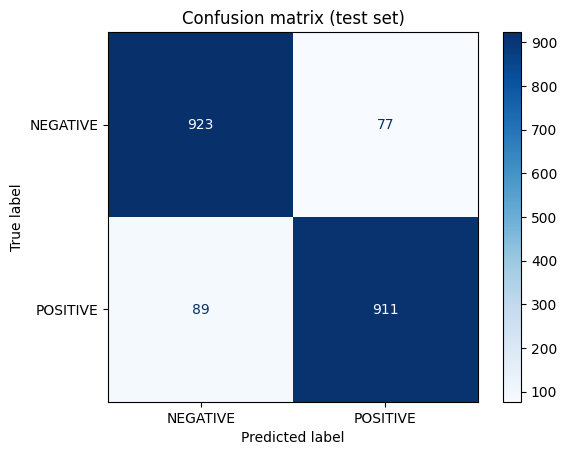

                                                                   review   actual predicted
This is one of the films that killed the "spaghetti" western. It not o... NEGATIVE  NEGATIVE
I was very moved by the gentle power of this movie and by the mood it ... POSITIVE  POSITIVE
This show is absolutely fantastic. It provides all the great drama and... POSITIVE  POSITIVE
Considering the film’s reputation as truly the worst of the worst, I w... NEGATIVE  NEGATIVE
Haha, what a great little movie! Wayne Crawford strikes again, or rath... POSITIVE  POSITIVE


In [7]:
# Training loss curve
log = pd.DataFrame(trainer.state.log_history)
log.dropna(subset=["loss"]).plot(x="step", y="loss", title="Training loss", legend=False, figsize=(6, 3))
plt.ylabel("loss"); plt.show()

# Evaluation on the test set
metrics = trainer.evaluate()
results = {k: round(metrics[f"eval_{k}"], 4) for k in ["accuracy", "precision", "recall", "f1"]}
print("Test metrics:", results, "\n")

pred_out = trainer.predict(tok_test)
y_true, y_pred = pred_out.label_ids, pred_out.predictions.argmax(-1)
print(classification_report(y_true, y_pred, target_names=list(ID2LABEL.values()), digits=4))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=list(ID2LABEL.values()), cmap="Blues")
plt.title("Confusion matrix (test set)"); plt.show()

# Predicted vs actual labels for a few test reviews
head = test_ds[:5]["text"]
print(pd.DataFrame({"review": [t[:70] + "..." for t in head],
                    "actual": [ID2LABEL[int(i)] for i in y_true[:5]],
                    "predicted": [ID2LABEL[int(i)] for i in y_pred[:5]]}).to_string(index=False))

In [8]:
# Test the model on new text inputs
@torch.no_grad()
def predict(texts):
    model.eval()
    enc = tok(texts, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt").to(model.device)
    probs = model(**enc).logits.softmax(-1).cpu()
    return [(ID2LABEL[int(p.argmax())], round(float(p.max()), 3)) for p in probs]

new_texts = ["A wonderful, moving film with brilliant performances.",
             "Dull, predictable and far too long. I want my money back.",
             "The soundtrack was great and the ending surprised me."]
for text, (label, conf) in zip(new_texts, predict(new_texts)):
    print(f"{label:8s} ({conf:.3f})  {text}")

# Save the fine-tuned model and tokenizer, then reload to verify
SAVE_DIR = "bert_imdb_model"
trainer.save_model(SAVE_DIR)
tok.save_pretrained(SAVE_DIR)
clf = pipeline("text-classification", model=SAVE_DIR, device=0 if DEVICE == "cuda" else -1)
print("\nReloaded from disk:", clf("An absolutely fantastic movie, I loved every minute."))

POSITIVE (0.992)  A wonderful, moving film with brilliant performances.
NEGATIVE (0.968)  Dull, predictable and far too long. I want my money back.
POSITIVE (0.990)  The soundtrack was great and the ending surprised me.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Reloaded from disk: [{'label': 'POSITIVE', 'score': 0.9910607933998108}]


## PART C: SEQUENCE-TO-SEQUENCE APPLICATION USING T5-SMALL
T5 treats every task as text-to-text, selected with a task prefix (`summarize:`, `translate English to German:`).

In [9]:
banner("PART C: SEQ2SEQ WITH T5-SMALL")
t5_tok = AutoTokenizer.from_pretrained("google-t5/t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("google-t5/t5-small").to(DEVICE).eval()

def generate(text, prefix, **kwargs):
    enc = t5_tok(prefix + text, return_tensors="pt", truncation=True, max_length=512).to(DEVICE)
    out = t5.generate(**enc, **kwargs)
    return t5_tok.decode(out[0], skip_special_tokens=True)

articles = {
    "Technology": "Transformer models have transformed natural language processing since they were introduced in 2017. "
                  "Unlike earlier recurrent networks, they process all words in a sentence in parallel and use self-attention "
                  "to decide which words matter most for each other. This makes training faster and lets models capture "
                  "long-range context. Pretrained models such as BERT and T5 are now fine-tuned for tasks like sentiment "
                  "analysis, translation and summarization, often with only a small amount of labelled data.",
    "Transport": "Electric vehicles are becoming more common in Indian cities as battery prices fall and charging networks "
                 "expand. Several state governments now offer subsidies and lower road taxes for buyers, while manufacturers "
                 "have launched affordable electric scooters and compact cars. Experts say the biggest remaining challenges "
                 "are the limited number of public chargers in smaller towns and the cost of replacing batteries. If these "
                 "gaps are closed, electric vehicles could significantly cut urban air pollution and fuel imports.",
    "Education": "A local university has introduced a new programme that lets students spend one semester working on real "
                 "projects with partner companies. Participants join small teams, receive guidance from both faculty and "
                 "industry mentors, and present their results at the end of the term. Early feedback from students has been "
                 "positive, with many saying the experience improved their teamwork and communication skills. The university "
                 "plans to double the number of places next year if the pilot continues to succeed.",
}

SETTINGS = {
    "greedy, max 20":   dict(num_beams=1, do_sample=False, max_new_tokens=20),
    "greedy, max 60":   dict(num_beams=1, do_sample=False, max_new_tokens=60),
    "beam=4, max 60":   dict(num_beams=4, early_stopping=True, no_repeat_ngram_size=3, max_new_tokens=60),
    "sampling, max 60": dict(do_sample=True, top_p=0.9, temperature=0.8, max_new_tokens=60),
}

# Task 1: summarization with different inputs and generation settings
records = []
for name, text in articles.items():
    print(f"\n### INPUT [{name}] ({len(text.split())} words)\n{textwrap.fill(text, 100)}\n")
    for setting, kw in SETTINGS.items():
        set_seed(SEED)
        out = generate(text, "summarize: ", **kw)
        records.append(dict(task="summarization", input=name, setting=setting, source=text, output=out))
        print(f"  [{setting}]  {out}")

PART C: SEQ2SEQ WITH T5-SMALL  |  Abhishek J  |  Roll No: 24BAD002


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]


### INPUT [Technology] (75 words)
Transformer models have transformed natural language processing since they were introduced in 2017.
Unlike earlier recurrent networks, they process all words in a sentence in parallel and use self-
attention to decide which words matter most for each other. This makes training faster and lets
models capture long-range context. Pretrained models such as BERT and T5 are now fine-tuned for
tasks like sentiment analysis, translation and summarization, often with only a small amount of
labelled data.

  [greedy, max 20]  Transformer models have transformed natural language processing since they were introduced in 2017. they process all words in
  [greedy, max 60]  Transformer models have transformed natural language processing since they were introduced in 2017. they process all words in a sentence in parallel and use self-attention to decide which words matter most for each other. this makes training faster and lets models capture long-range context.
  [b

In [10]:
# Task 2: translation (same model, different task prefix)
sentences = ["The weather is beautiful today, so we are going to the beach.",
             "Transformers have made machine translation faster and more accurate."]
for lang in ["German", "French"]:
    for s in sentences:
        out = generate(s, f"translate English to {lang}: ", num_beams=4, early_stopping=True, max_new_tokens=60)
        records.append(dict(task=f"translation (EN->{lang[:2].upper()})", input=s[:30] + "...",
                            setting="beam=4, max 60", source=s, output=out))
        print(f"EN: {s}\n{lang[:2].upper()}: {out}\n")

# Save generated outputs for further analysis
gen_df = pd.DataFrame(records)
gen_df.to_csv("generated_outputs.csv", index=False)
print(f"Saved {len(gen_df)} generated outputs to generated_outputs.csv")

EN: The weather is beautiful today, so we are going to the beach.
GE: Das Wetter ist heute schön, also gehen wir zum Strand.

EN: Transformers have made machine translation faster and more accurate.
GE: Die Transformatoren haben die Übersetzung der Maschinen schneller und präziser gemacht.

EN: The weather is beautiful today, so we are going to the beach.
FR: Le temps est beau aujourd'hui, donc nous allons à la plage.

EN: Transformers have made machine translation faster and more accurate.
FR: Les transformateurs ont rendu la traduction des machines plus rapide et plus précise.

Saved 16 generated outputs to generated_outputs.csv


## PART D: MODEL TESTING AND OUTPUT ANALYSIS

In [11]:
banner("PART D: BERT CLASSIFICATION TESTING")
tests = [
    ("An absolutely brilliant film with superb acting and a moving story.", "POSITIVE"),
    ("One of the best movies I have seen this year. Highly recommended!", "POSITIVE"),
    ("Terrible plot, wooden acting and a painfully boring ending.", "NEGATIVE"),
    ("I wasted two hours of my life on this awful movie.", "NEGATIVE"),
    ("Not bad at all, I actually enjoyed it more than I expected.", "POSITIVE"),                 # negation
    ("Oh great, another predictable sequel. Just what the world needed.", "NEGATIVE"),          # sarcasm
    ("The visuals were stunning, but the story was dull and the pacing dragged.", "NEGATIVE"),  # mixed
]
preds = predict([t for t, _ in tests])
test_df = pd.DataFrame({"text": [t[:62] + "..." for t, _ in tests], "expected": [e for _, e in tests],
                        "predicted": [p[0] for p in preds], "confidence": [p[1] for p in preds]})
test_df["correct"] = test_df.expected == test_df.predicted
print(test_df.to_string(index=False))
print(f"\nSample accuracy: {test_df.correct.mean():.0%} | Full test-set metrics: {results}")

wrong = np.where(y_true != y_pred)[0]
print(f"\nMisclassified: {len(wrong)}/{len(y_true)} test reviews. Examples:")
for i in wrong[:3]:
    print(f"\n[{ID2LABEL[int(y_true[i])]} -> predicted {ID2LABEL[int(y_pred[i])]}] {test_ds[int(i)]['text'][:250]}...")

PART D: BERT CLASSIFICATION TESTING  |  Abhishek J  |  Roll No: 24BAD002
                                                             text expected predicted  confidence  correct
An absolutely brilliant film with superb acting and a moving s... POSITIVE  POSITIVE       0.993     True
One of the best movies I have seen this year. Highly recommend... POSITIVE  POSITIVE       0.993     True
   Terrible plot, wooden acting and a painfully boring ending.... NEGATIVE  NEGATIVE       0.992     True
            I wasted two hours of my life on this awful movie.... NEGATIVE  NEGATIVE       0.976     True
   Not bad at all, I actually enjoyed it more than I expected.... POSITIVE  POSITIVE       0.785     True
Oh great, another predictable sequel. Just what the world need... NEGATIVE  NEGATIVE       0.962     True
The visuals were stunning, but the story was dull and the paci... NEGATIVE  NEGATIVE       0.991     True

Sample accuracy: 100% | Full test-set metrics: {'accuracy': 0.917, 'precision'

In [12]:
banner("PART D: T5 GENERATION ANALYSIS")
words = lambda s: re.findall(r"\w+", s.lower())

def stats(row):
    src, out = words(row["source"]), words(row["output"])
    bigrams = list(zip(out, out[1:]))
    return pd.Series({
        "words": len(out),
        "compression": len(out) / len(src),
        "in_source_%": 100 * np.mean([w in set(src) for w in out]) if out else 0,
        "repeat_bigram_%": 100 * (1 - len(set(bigrams)) / len(bigrams)) if bigrams else 0,
    })

summ = gen_df[gen_df.task == "summarization"].reset_index(drop=True)
summ = summ.join(summ.apply(stats, axis=1))
print("Average over the 3 articles, by generation setting:")
print(summ.groupby("setting", sort=False)[["words", "compression", "in_source_%", "repeat_bigram_%"]].mean().round(2))

print("\nSummary of both models")
print(f"BERT classifier : accuracy {results['accuracy']:.2%}, F1 {results['f1']:.2%} on {len(y_true)} unseen test reviews")
print(f"T5-small        : {len(gen_df)} outputs generated and saved to generated_outputs.csv")

PART D: T5 GENERATION ANALYSIS  |  Abhishek J  |  Roll No: 24BAD002
Average over the 3 articles, by generation setting:
                  words  compression  in_source_%  repeat_bigram_%
setting                                                           
greedy, max 20    17.00         0.22        96.08              0.0
greedy, max 60    32.33         0.42        97.85              0.0
beam=4, max 60    41.67         0.54        99.07              0.0
sampling, max 60  30.33         0.39        89.72              0.0

Summary of both models
BERT classifier : accuracy 91.70%, F1 91.65% on 2000 unseen test reviews
T5-small        : 16 outputs generated and saved to generated_outputs.csv
